# CA2, Phase 1: DCF and the slotted contention model

This notebook is **optional**: any language or tool is fine for the analysis (see the setup section of the assignment). It only **loads** simulation results; the model, the plots and the analysis are yours to write, in new cells under each section heading.

Rules:
- Your group's parameters come from `../params.json` (written by `ca2_params.py`). Do not type L or R by hand.
- Every number and plot in your report must be reproducible from the code you hand in; the TAs do not run it, but at the in-person delivery you will rerun parts of it and change them.

In [1]:
import json
import os
import glob
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from omnetpp.scave import results
    HAS_SCAVE = True
except ImportError:
    HAS_SCAVE = False
    print("Note: omnetpp.scave not installed in this environment; using built-in pure-Python results parser.")

with open(os.path.join("..", "params.json")) as f:
    P = json.load(f)
L, R = P["L"], P["R"]
print(f"students: {', '.join(P['students'])}")
print(f"L = {L} B, R = {R} Mbps")

# Directory for saving report figures
FIGURES_DIR = os.path.join("..", "report", "figures")
os.makedirs(FIGURES_DIR, exist_ok=True)


Note: omnetpp.scave not installed in this environment; using built-in pure-Python results parser.
students: 810102460, 810102585
L = 1350 B, R = 12 Mbps


## Loading results

`load_scalars(config)` returns every scalar of one config, with its iteration variables (for example `n` or `rtsThreshold`) and `repetition` as columns.
`scalar(sc, module, name)` returns one value per run: the scalar `name`, summed over all modules whose full path matches the regular expression `module`.

In [2]:
RESULTS = "results"


def load_scalars(config):
    if HAS_SCAVE:
        df = results.read_result_files(os.path.join(RESULTS, f"{config}-*.sca"))
        sc = results.get_scalars(df, include_itervars=True, include_runattrs=True)
        for col in ("n", "repetition"):
            if col in sc:
                sc[col] = pd.to_numeric(sc[col])
        return sc
    else:
        files = glob.glob(os.path.join(RESULTS, f"{config}-*.sca"))
        records = []
        for fp in files:
            attrs = {}
            with open(fp, "r", encoding="utf-8", errors="ignore") as f:
                for line in f:
                    line = line.strip()
                    if line.startswith("itervar ") or line.startswith("attr "):
                        parts = line.split(maxsplit=2)
                        if len(parts) >= 3:
                            attrs[parts[1]] = parts[2].strip('"')
                    elif line.startswith("scalar "):
                        parts = line.split()
                        if len(parts) >= 4:
                            mod = parts[1]
                            name = parts[2]
                            try:
                                val = float(parts[3])
                            except ValueError:
                                continue
                            rec = {"module": mod, "name": name, "value": val}
                            rec.update(attrs)
                            records.append(rec)
        df = pd.DataFrame(records)
        for col in ("n", "repetition"):
            if col in df:
                df[col] = pd.to_numeric(df[col], errors="coerce")
        return df


def scalar(sc, module, name):
    rows = sc[(sc.name == name) & sc.module.str.fullmatch(module)]
    keys = [c for c in ("n", "rtsThreshold", "repetition") if c in rows and rows[c].notna().all()]
    return rows.groupby(keys).value.sum()


def load_vector(config, module, name):
    if HAS_SCAVE:
        df = results.read_result_files(os.path.join(RESULTS, f"{config}-*.vec"))
        v = results.get_vectors(df)
        row = v[(v.module == module) & (v.name == name)].iloc[0]
        return row.vectime, row.vecvalue
    else:
        files = glob.glob(os.path.join(RESULTS, f"{config}-*.vec"))
        for fp in files:
            target_vid = None
            vectime = []
            vecvalue = []
            with open(fp, "r", encoding="utf-8", errors="ignore") as f:
                for line in f:
                    line = line.strip()
                    if line.startswith("vector ") and module in line and name in line:
                        parts = line.split()
                        target_vid = parts[1]
                    elif target_vid is not None and (line.startswith(target_vid + "\t") or line.startswith(target_vid + " ")):
                        parts = line.split()
                        if len(parts) >= 4:
                            vectime.append(float(parts[2]))
                            vecvalue.append(float(parts[3]))
                        elif len(parts) == 3:
                            vectime.append(float(parts[1]))
                            vecvalue.append(float(parts[2]))
            if target_vid is not None and len(vectime) > 0:
                return np.array(vectime), np.array(vecvalue)
        raise ValueError(f"Vector {name} not found in module {module}")


Example: frames received by the AP in each run of the `Hidden` config (run that config first).

In [3]:
hidden = load_scalars("Hidden")
scalar(hidden, r"Contention\.ap\.sink", "packets:count")

rtsThreshold  repetition
100B          0             7406.0
              1             7296.0
              2             7333.0
              3             7425.0
              4             7442.0
3000B         0             5807.0
              1             5796.0
              2             5748.0
              3             5827.0
              4             5867.0
Name: value, dtype: float64

## 1-1  A single exchange up close

In [4]:
# 1-1: Frame exchange timing calculations
import math

# Protocol & Physical constants (802.11a)
sigma = 9e-6      # slot time: 9 us
sifs = 16e-6      # SIFS: 16 us
difs = sifs + 2 * sigma # DIFS: 34 us
cw_min = 15
cw_max = 1023

# Frame sizes (Bytes)
# Data frame: Payload (1350) + LLC (3) + MAC Data Header (24) + FCS (4) = 1381 B
B_data = 1381
# ACK frame: Frame Control (2) + Duration (2) + RA (6) + FCS (4) = 14 B
B_ack = 14

def calc_t_ppdu(B, r):
    N_DBPS = 4 * r
    symbols = math.ceil((16 + 8 * B + 6) / N_DBPS)
    return 20e-6 + 4e-6 * symbols

T_data = calc_t_ppdu(B_data, R) # 944 us
T_ack = calc_t_ppdu(B_ack, 12.0) # 32 us

# Expected backoff slots for n=1
k_bar = cw_min / 2.0 # 7.5
T_cycle_1 = difs + k_bar * sigma + T_data + sifs + T_ack
S_1 = (8 * L) / T_cycle_1

print('--- Q3-1 & Q3-2 Timings ---')
print(f'DIFS: {difs*1e6:.1f} us, SIFS: {sifs*1e6:.1f} us, slot: {sigma*1e6:.1f} us')
print(f'DATA PPDU: {T_data*1e6:.1f} us (B = {B_data} B, R = {R} Mbps)')
print(f'ACK PPDU:  {T_ack*1e6:.1f} us (B = {B_ack} B, R_ack = 12 Mbps)')
print('\n--- Q3-3 Single Station Throughput ---')
print(f'k_bar = {k_bar} slots ({k_bar*sigma*1e6:.1f} us)')
print(f'Cycle time T_cycle = {T_cycle_1*1e6:.1f} us')
print(f'Theoretical S_1 = {S_1/1e6:.4f} Mbps')

# Measured from simulation for n=1
sweep_sc = load_scalars('Sweep')
n1_pkts = scalar(sweep_sc[sweep_sc.n == 1], r'Contention\.ap\.sink', 'packets:count').mean()
S_sim_1 = (8 * L * n1_pkts) / 10.0 / 1e6
print(f'Simulation S_sim(1) = {S_sim_1:.4f} Mbps')
print(f'Relative error: {abs(S_1/1e6 - S_sim_1) / (S_1/1e6) * 100:.3f}%')


--- Q3-1 & Q3-2 Timings ---
DIFS: 34.0 us, SIFS: 16.0 us, slot: 9.0 us
DATA PPDU: 944.0 us (B = 1381 B, R = 12 Mbps)
ACK PPDU:  32.0 us (B = 14 B, R_ack = 12 Mbps)

--- Q3-3 Single Station Throughput ---
k_bar = 7.5 slots (67.5 us)
Cycle time T_cycle = 1093.5 us
Theoretical S_1 = 9.8765 Mbps
Simulation S_sim(1) = 9.8749 Mbps
Relative error: 0.017%


## 1-2  The slotted contention model

Saved figure: ..\report\figures\phase1_slotted_model.png


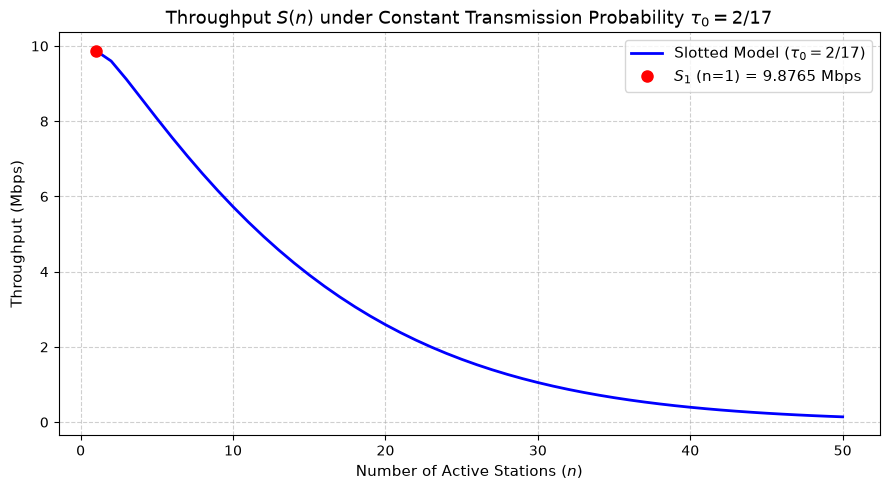

Peak throughput occurs at n = 1 (9.8765 Mbps)
Throughput at n = 30: 1.0533 Mbps
Throughput at n = 50: 0.1411 Mbps


In [5]:
# 1-2: Slotted Contention Model Implementation
tau_0 = 2.0 / (cw_min + 2.0) # 2/17 ≈ 0.117647
Ts = difs + T_data + sifs + T_ack # 1026 us
Tc = difs + T_data # 978 us

def slotted_model_throughput(n_arr, tau_val):
    S_arr = []
    for n in n_arr:
        P_idle = (1.0 - tau_val)**n
        Ps = n * tau_val * (1.0 - tau_val)**(n - 1)
        Pc = 1.0 - P_idle - Ps
        denom = P_idle * sigma + Ps * Ts + Pc * Tc
        S = (Ps * 8 * L) / denom
        S_arr.append(S / 1e6)
    return np.array(S_arr)

n_range = np.arange(1, 51)
S_tau0_curve = slotted_model_throughput(n_range, tau_0)

plt.figure(figsize=(9, 5))
plt.plot(n_range, S_tau0_curve, 'b-', lw=2, label=r'Slotted Model ($\tau_0 = 2/17$)')
plt.plot(1, S_1/1e6, 'ro', markersize=8, label=f'$S_1$ (n=1) = {S_1/1e6:.4f} Mbps')
plt.title(r'Throughput $S(n)$ under Constant Transmission Probability $\tau_0 = 2/17$', fontsize=13)
plt.xlabel('Number of Active Stations ($n$)', fontsize=11)
plt.ylabel('Throughput (Mbps)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
fig_path_m = os.path.join(FIGURES_DIR, "phase1_slotted_model.png")
plt.savefig(fig_path_m, dpi=300, bbox_inches='tight')
print(f"Saved figure: {fig_path_m}")
plt.show()

print(f'Peak throughput occurs at n = {n_range[np.argmax(S_tau0_curve)]} ({np.max(S_tau0_curve):.4f} Mbps)')
print(f'Throughput at n = 30: {S_tau0_curve[29]:.4f} Mbps')
print(f'Throughput at n = 50: {S_tau0_curve[49]:.4f} Mbps')


## 1-3  Model versus simulator

 n  Sim_S  Sim_CI  p_hat  tau_hat  Model_tau0  Model_tauhat  Err_tau0_%  Err_tauhat_%
 1 9.8749  0.0028 0.0000   0.1176      9.8765        9.8765        0.02          0.02
 2 9.5552  0.0526 0.1065   0.1065      9.6004        9.6254        0.47          0.73
 3 9.2182  0.0140 0.1794   0.0942      9.1163        9.3100        1.11          1.00
 5 8.7841  0.0305 0.2605   0.0727      8.0750        8.8909        8.07          1.22
 8 8.3920  0.0386 0.3274   0.0551      6.6049        8.5044       21.30          1.34
10 8.1618  0.0448 0.3649   0.0492      5.7276        8.2722       29.82          1.35
15 7.7924  0.0776 0.4200   0.0382      3.9131        7.9086       49.78          1.49
20 7.5054  0.0516 0.4598   0.0319      2.5917        7.6286       65.47          1.64
25 7.2935  0.0173 0.4891   0.0276      1.6712        7.4126       77.09          1.63
30 7.1325  0.0415 0.5113   0.0244      1.0533        7.2429       85.23          1.55
Saved figure: ..\report\figures\phase1_sim_vs_models.p

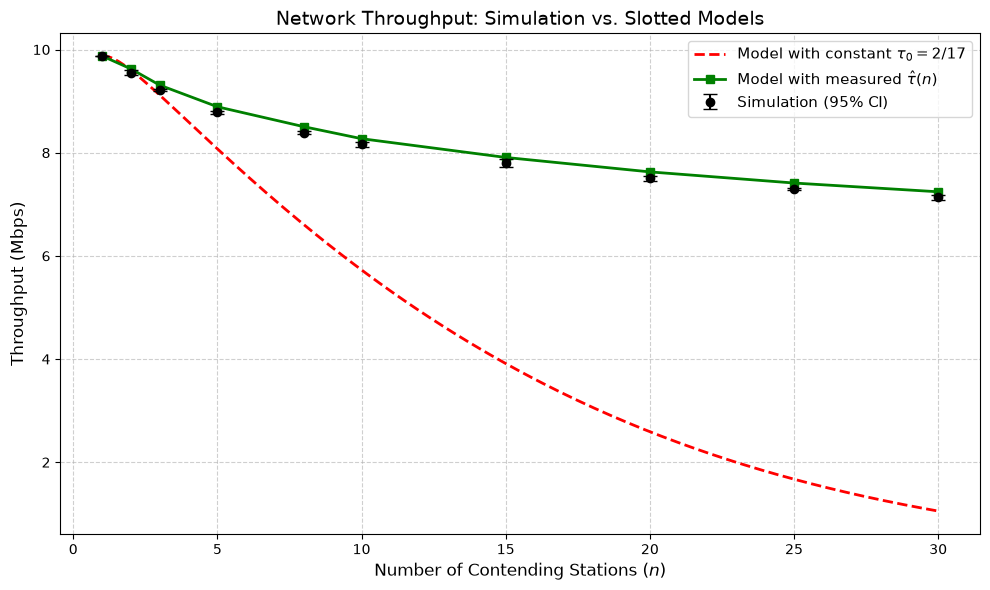

Saved figure: ..\report\figures\phase1_cw_trace.png


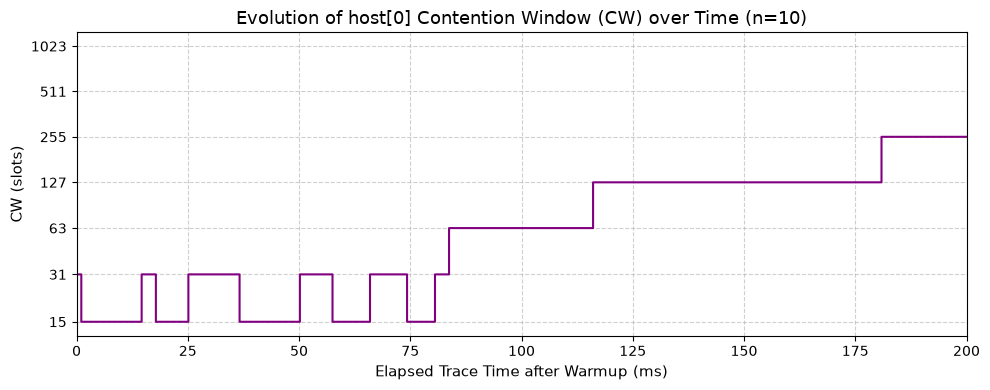

In [6]:
# 1-3: Model vs. Simulation Comparison
sweep_scalars = load_scalars('Sweep')

# Extract throughput S per run
sweep_pkts = sweep_scalars[(sweep_scalars.name == 'packets:count') & sweep_scalars.module.str.fullmatch(r'Contention\.ap\.sink')].copy()
sweep_pkts['S_Mbps'] = (8 * L * sweep_pkts['value']) / 10.0 / 1e6

# Extract retry and drop stats for p_hat and tau_hat
n_first_s = scalar(sweep_scalars, r'Contention\.host\[\d+\]\.wlan\.mac\.dcf', 'packetSentToPeerWithoutRetry:count')
n_retry_s = scalar(sweep_scalars, r'Contention\.host\[\d+\]\.wlan\.mac\.dcf', 'packetSentToPeerWithRetry:count')
n_drop_s = scalar(sweep_scalars, r'Contention\.host\[\d+\]\.wlan\.mac\.dcf', 'packetDropRetryLimitReached:count')

stats_df = pd.DataFrame({'N_first': n_first_s, 'N_retry': n_retry_s, 'N_drop': n_drop_s}).reset_index()
stats_df['p_hat'] = (stats_df['N_retry'] + stats_df['N_drop']) / (stats_df['N_retry'] + stats_df['N_first'])
stats_df['tau_hat'] = np.where(stats_df['n'] > 1, 1.0 - (1.0 - stats_df['p_hat'])**(1.0 / (stats_df['n'] - 1)), tau_0)

# Merge stats
merged = pd.merge(sweep_pkts[['n', 'repetition', 'S_Mbps']], stats_df[['n', 'repetition', 'p_hat', 'tau_hat']], on=['n', 'repetition'])

# Group by n
summary = []
t_crit = 2.776 # 95% CI with df = 4
for n_val, group in merged.groupby('n'):
    s_mean = group['S_Mbps'].mean()
    s_ci = t_crit * group['S_Mbps'].std() / np.sqrt(len(group))
    p_mean = group['p_hat'].mean()
    tau_mean = group['tau_hat'].mean()
    
    P_idle_0 = (1.0 - tau_0)**n_val
    Ps_0 = n_val * tau_0 * (1.0 - tau_0)**(n_val - 1)
    Pc_0 = 1.0 - P_idle_0 - Ps_0
    S_tau0 = (Ps_0 * 8 * L) / (P_idle_0 * sigma + Ps_0 * Ts + Pc_0 * Tc) / 1e6
    
    P_idle_hat = (1.0 - tau_mean)**n_val
    Ps_hat = n_val * tau_mean * (1.0 - tau_mean)**(n_val - 1)
    Pc_hat = 1.0 - P_idle_hat - Ps_hat
    S_tauhat = (Ps_hat * 8 * L) / (P_idle_hat * sigma + Ps_hat * Ts + Pc_hat * Tc) / 1e6
    
    summary.append({
        'n': int(n_val),
        'Sim_S': round(s_mean, 4),
        'Sim_CI': round(s_ci, 4),
        'p_hat': round(p_mean, 4),
        'tau_hat': round(tau_mean, 4),
        'Model_tau0': round(S_tau0, 4),
        'Model_tauhat': round(S_tauhat, 4),
        'Err_tau0_%': round(abs(s_mean - S_tau0) / s_mean * 100, 2),
        'Err_tauhat_%': round(abs(s_mean - S_tauhat) / s_mean * 100, 2)
    })

sum_res = pd.DataFrame(summary).sort_values('n')
print(sum_res.to_string(index=False))

# Plotting Comparison
plt.figure(figsize=(10, 6))
plt.errorbar(sum_res['n'], sum_res['Sim_S'], yerr=sum_res['Sim_CI'], fmt='o', color='black', capsize=5, label='Simulation (95% CI)', zorder=5)
n_dense = np.linspace(1, 30, 200)
plt.plot(n_dense, slotted_model_throughput(n_dense, tau_0), 'r--', lw=2, label=r'Model with constant $\tau_0 = 2/17$')
plt.plot(sum_res['n'], sum_res['Model_tauhat'], 'g-s', lw=2, markersize=6, label=r'Model with measured $\hat{\tau}(n)$')
plt.title('Network Throughput: Simulation vs. Slotted Models', fontsize=14)
plt.xlabel('Number of Contending Stations ($n$)', fontsize=12)
plt.ylabel('Throughput (Mbps)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
fig_path1 = os.path.join(FIGURES_DIR, "phase1_sim_vs_models.png")
plt.savefig(fig_path1, dpi=300, bbox_inches='tight')
print(f"Saved figure: {fig_path1}")
plt.show()

# Contention window trace
cw_time, cw_val = load_vector('CwTrace', 'Contention.host[0].wlan.mac.dcf.recoveryProcedure', 'contentionWindowChanged:vector')
# Align trace timestamps after the 2s warmup period so the backoff progression is visible
cw_time_ms = (cw_time - cw_time[0]) * 1e3 if len(cw_time) > 0 and cw_time[0] >= 1.0 else cw_time * 1e3
plt.figure(figsize=(10, 4))
plt.step(cw_time_ms, cw_val, where='post', color='purple', lw=1.5)
plt.title('Evolution of host[0] Contention Window (CW) over Time (n=10)', fontsize=13)
plt.xlabel('Elapsed Trace Time after Warmup (ms)', fontsize=11)
plt.ylabel('CW (slots)', fontsize=11)
plt.yscale('log', base=2)
plt.yticks([15, 31, 63, 127, 255, 511, 1023], ['15', '31', '63', '127', '255', '511', '1023'])
plt.grid(True, which='both', linestyle='--', alpha=0.6)
plt.xlim(0, 200)
plt.tight_layout()
fig_path2 = os.path.join(FIGURES_DIR, "phase1_cw_trace.png")
plt.savefig(fig_path2, dpi=300, bbox_inches='tight')
print(f"Saved figure: {fig_path2}")
plt.show()


## 1-4  Hidden terminal and RTS/CTS

--- Hidden Terminal Results (Per Repetition) ---
rtsThreshold  repetition   S_tot     S_0     S_1     Jain
        100B           0 7.99848 4.17798 3.82050 0.998006
        100B           1 7.87968 3.58614 4.29354 0.992005
        100B           2 7.91964 4.09914 3.82050 0.998764
        100B           3 8.01900 3.52620 4.49280 0.985679
        100B           4 8.03736 4.06620 3.97116 0.999860
       3000B           0 6.27156 4.41072 1.86084 0.858144
       3000B           1 6.25968 4.88808 1.37160 0.760120
       3000B           2 6.20784 2.92464 3.28212 0.996694
       3000B           3 6.29316 2.64276 3.65040 0.975003
       3000B           4 6.33636 5.91408 0.42228 0.571040

--- Summary by RTS Threshold ---
RTS Threshold: 100B
  Total Throughput (Mbps): 7.9708 +/- 0.0843
  Host[0] Throughput (Mbps): 3.8911
  Host[1] Throughput (Mbps): 4.0797
  Jain Fairness Index: 0.9949
RTS Threshold: 3000B
  Total Throughput (Mbps): 6.2737 +/- 0.0584
  Host[0] Throughput (Mbps): 4.1561
  Host[1] 

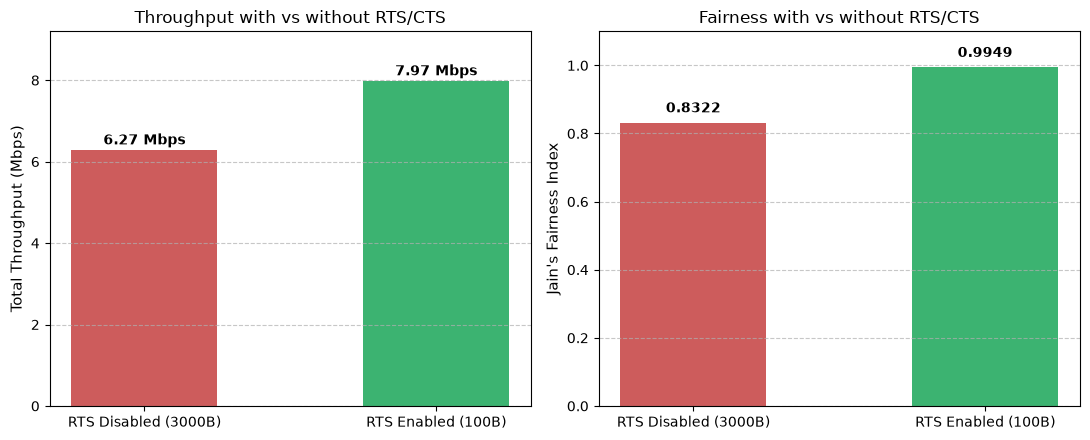

In [7]:
# 1-4: Hidden Terminal and RTS/CTS Evaluation
hidden_scalars = load_scalars('Hidden')

ap_pkts = hidden_scalars[(hidden_scalars.name == 'packets:count') & hidden_scalars.module.str.fullmatch(r'Contention\.ap\.sink')].copy()
ap_pkts['S_tot'] = (8 * L * ap_pkts['value']) / 10.0 / 1e6

h0_pkts = scalar(hidden_scalars, r'Contention\.host\[0\]\.wlan\.mac\.dcf', 'packetReceivedFromPeer:count')
h1_pkts = scalar(hidden_scalars, r'Contention\.host\[1\]\.wlan\.mac\.dcf', 'packetReceivedFromPeer:count')

h_df = pd.DataFrame({'h0': h0_pkts, 'h1': h1_pkts}).reset_index()
h_df['h0_succ'] = np.where(h_df['rtsThreshold'] == '100B', h_df['h0'] / 2.0, h_df['h0'])
h_df['h1_succ'] = np.where(h_df['rtsThreshold'] == '100B', h_df['h1'] / 2.0, h_df['h1'])

h_df['S_0'] = (8 * L * h_df['h0_succ']) / 10.0 / 1e6
h_df['S_1'] = (8 * L * h_df['h1_succ']) / 10.0 / 1e6
h_df['Jain'] = ((h_df['S_0'] + h_df['S_1'])**2) / (2.0 * (h_df['S_0']**2 + h_df['S_1']**2))

h_merged = pd.merge(ap_pkts[['rtsThreshold', 'repetition', 'S_tot']], h_df[['rtsThreshold', 'repetition', 'S_0', 'S_1', 'Jain']], on=['rtsThreshold', 'repetition'])

print('--- Hidden Terminal Results (Per Repetition) ---')
print(h_merged[['rtsThreshold', 'repetition', 'S_tot', 'S_0', 'S_1', 'Jain']].to_string(index=False))

print('\n--- Summary by RTS Threshold ---')
for rts, g in h_merged.groupby('rtsThreshold'):
    ci = 2.776 * g['S_tot'].std() / np.sqrt(len(g))
    print(f'RTS Threshold: {rts}')
    print(f'  Total Throughput (Mbps): {g["S_tot"].mean():.4f} +/- {ci:.4f}')
    print(f'  Host[0] Throughput (Mbps): {g["S_0"].mean():.4f}')
    print(f'  Host[1] Throughput (Mbps): {g["S_1"].mean():.4f}')
    print(f'  Jain Fairness Index: {g["Jain"].mean():.4f}')

# Plotting RTS/CTS Comparison
labels = ['RTS Disabled (3000B)', 'RTS Enabled (100B)']
tot_means = [h_merged[h_merged.rtsThreshold == '3000B']['S_tot'].mean(), h_merged[h_merged.rtsThreshold == '100B']['S_tot'].mean()]
jain_means = [h_merged[h_merged.rtsThreshold == '3000B']['Jain'].mean(), h_merged[h_merged.rtsThreshold == '100B']['Jain'].mean()]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
ax1.bar(labels, tot_means, color=['indianred', 'mediumseagreen'], width=0.5)
ax1.set_ylabel('Total Throughput (Mbps)', fontsize=11)
ax1.set_title('Throughput with vs without RTS/CTS', fontsize=12)
ax1.set_ylim(0, 9.2)
ax1.grid(True, axis='y', linestyle='--', alpha=0.7)
for i, v in enumerate(tot_means):
    ax1.text(i, v + 0.15, f'{v:.2f} Mbps', ha='center', fontweight='bold')

ax2.bar(labels, jain_means, color=['indianred', 'mediumseagreen'], width=0.5)
ax2.set_ylabel("Jain's Fairness Index", fontsize=11)
ax2.set_title('Fairness with vs without RTS/CTS', fontsize=12)
ax2.set_ylim(0, 1.1)
ax2.grid(True, axis='y', linestyle='--', alpha=0.7)
for i, v in enumerate(jain_means):
    ax2.text(i, v + 0.03, f'{v:.4f}', ha='center', fontweight='bold')

plt.tight_layout()
fig_path_h = os.path.join(FIGURES_DIR, "phase1_hidden_rts_comparison.png")
plt.savefig(fig_path_h, dpi=300, bbox_inches='tight')
print(f"Saved figure: {fig_path_h}")
plt.show()
